upload file from directory


In [57]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Import libraries

In [58]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


Print dataset's dimension and read first rows

In [59]:
df = pd.read_csv('/content/drive/MyDrive/Data analytics final/Resources/StudentPerformanceFactors.csv')
print(df.shape)
df.head(10)

(6607, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70
5,19,88,Medium,Medium,Yes,8,89,Medium,Yes,3,Medium,Medium,Public,Positive,3,No,Postgraduate,Near,Male,71
6,29,84,Medium,Low,Yes,7,68,Low,Yes,1,Low,Medium,Private,Neutral,2,No,High School,Moderate,Male,67
7,25,78,Low,High,Yes,6,50,Medium,Yes,1,High,High,Public,Negative,2,No,High School,Far,Male,66
8,17,94,Medium,High,No,6,80,High,Yes,0,Medium,Low,Private,Neutral,1,No,College,Near,Male,69
9,23,98,Medium,Medium,Yes,8,71,Medium,Yes,0,High,High,Public,Positive,5,No,High School,Moderate,Male,72


In [60]:
# Creating Total_Study_Hours
df['Total_Study_Hours'] = df['Hours_Studied'] + df['Tutoring_Sessions']

df.head(10)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,...,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score,Total_Study_Hours
0,23,84,Low,High,No,7,73,Low,Yes,0,...,Medium,Public,Positive,3,No,High School,Near,Male,67,23
1,19,64,Low,Medium,No,8,59,Low,Yes,2,...,Medium,Public,Negative,4,No,College,Moderate,Female,61,21
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,...,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74,26
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,...,Medium,Public,Negative,4,No,High School,Moderate,Male,71,30
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,...,High,Public,Neutral,4,No,College,Near,Female,70,22
5,19,88,Medium,Medium,Yes,8,89,Medium,Yes,3,...,Medium,Public,Positive,3,No,Postgraduate,Near,Male,71,22
6,29,84,Medium,Low,Yes,7,68,Low,Yes,1,...,Medium,Private,Neutral,2,No,High School,Moderate,Male,67,30
7,25,78,Low,High,Yes,6,50,Medium,Yes,1,...,High,Public,Negative,2,No,High School,Far,Male,66,26
8,17,94,Medium,High,No,6,80,High,Yes,0,...,Low,Private,Neutral,1,No,College,Near,Male,69,17
9,23,98,Medium,Medium,Yes,8,71,Medium,Yes,0,...,High,Public,Positive,5,No,High School,Moderate,Male,72,23


### Data Preprocessing


Create a new feature by combining two different features together (Hours_Studied and Tutoring_Sessions)

In [61]:
# Creating Total_Study_Hours
df['Total_Study_Hours'] = df['Hours_Studied'] + df['Tutoring_Sessions']

# Drop the original features if they are no longer needed
#df = df.drop(columns=['Hours_Studied', 'Tutoring_Sessions'])

Keeping only key features

In [62]:
# Specify the key features you want to keep
#key_features = ['Hours_Studied', 'Attendance', 'Teacher_Quality']

key_features = ['Total_Study_Hours', 'Attendance', 'Previous_Scores', 'Access_to_Resources']

# Drop all columns except the key features
df_filtered = df[key_features]

# Display the filtered DataFrame
print(df_filtered)

      Total_Study_Hours  Attendance  Previous_Scores Access_to_Resources
0                    23          84               73                High
1                    21          64               59              Medium
2                    26          98               91              Medium
3                    30          89               98              Medium
4                    22          92               65              Medium
...                 ...         ...              ...                 ...
6602                 26          69               76              Medium
6603                 26          76               81              Medium
6604                 23          90               65                 Low
6605                 12          86               91                High
6606                 15          67               94                 Low

[6607 rows x 4 columns]


Print missing values of each feature


In [63]:
#Check for missing values
df_filtered.isnull().sum()

,0
Total_Study_Hours,0
Attendance,0
Previous_Scores,0
Access_to_Resources,0


Check dtype of each feature

In [64]:
print(df_filtered.dtypes)

Total_Study_Hours       int64
Attendance              int64
Previous_Scores         int64
Access_to_Resources    object
dtype: object


Encode categorical to numeric

In [65]:

from sklearn.preprocessing import LabelEncoder

# Initialize the label encoder
encoder = LabelEncoder()

# Apply label encoding to 'Teacher_Quality'
#H 0 , M 2, Low 1
df_filtered['Access_to_Resources'] = encoder.fit_transform(df_filtered['Access_to_Resources'])

print(df_filtered[['Access_to_Resources']].head(10))

   Access_to_Resources
0                    0
1                    2
2                    2
3                    2
4                    2
5                    2
6                    1
7                    0
8                    0
9                    2


/tmp/ipykernel_4901/248553536.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['Access_to_Resources'] = encoder.fit_transform(df_filtered['Access_to_Resources'])


In [66]:
df_filtered.dtypes

,0
Total_Study_Hours,int64
Attendance,int64
Previous_Scores,int64
Access_to_Resources,int64


Check for duplicate rows

In [67]:
# Check for duplicate rows
print(f"Duplicate rows: {df_filtered.duplicated().sum()}")

# Drop duplicate rows
df_filtered = df_filtered.drop_duplicates()

# Check again for duplicates
print(f"Duplicate rows after dropping: {df_filtered.duplicated().sum()}")


Duplicate rows: 178
Duplicate rows after dropping: 0


Removing outliers from the independent features

In [68]:
# Calculate Q1 (25th percentile) and Q3 (75th percentile) for the numerical columns
Q1 = df_filtered[['Total_Study_Hours', 'Attendance', 'Previous_Scores']].quantile(0.25)
Q3 = df_filtered[['Total_Study_Hours', 'Attendance', 'Previous_Scores']].quantile(0.75)
IQR = Q3 - Q1  # Calculate the Interquartile Range

# Define lower and upper bounds for outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter the DataFrame to remove rows with outliers
df_filtered = df_filtered[
    (df_filtered['Total_Study_Hours'] >= lower_bound['Total_Study_Hours']) &
    (df_filtered['Total_Study_Hours'] <= upper_bound['Total_Study_Hours']) &
    (df_filtered['Attendance'] >= lower_bound['Attendance']) &
    (df_filtered['Attendance'] <= upper_bound['Attendance']) &
    (df_filtered['Previous_Scores'] >= lower_bound['Previous_Scores']) &
    (df_filtered['Previous_Scores'] <= upper_bound['Previous_Scores'])

]

# Display the resulting DataFrame
print(df_filtered)



      Total_Study_Hours  Attendance  Previous_Scores  Access_to_Resources
0                    23          84               73                    0
1                    21          64               59                    2
2                    26          98               91                    2
3                    30          89               98                    2
4                    22          92               65                    2
...                 ...         ...              ...                  ...
6602                 26          69               76                    2
6603                 26          76               81                    2
6604                 23          90               65                    1
6605                 12          86               91                    0
6606                 15          67               94                    1

[6406 rows x 4 columns]


Add our target_variable into df_filtered

In [69]:
df_filtered['Exam_Score'] = df['Exam_Score']

Standardize the features to bring them to the same scale

In [70]:
from sklearn.preprocessing import StandardScaler

# Initialize the scaler
scaler = StandardScaler()

# Apply standardization to the numerical columns
df_filtered[['Total_Study_Hours', 'Attendance', 'Previous_Scores']] = scaler.fit_transform(df_filtered[['Total_Study_Hours', 'Attendance', 'Previous_Scores']])

print(df_filtered[['Total_Study_Hours', 'Attendance', 'Previous_Scores']].head())


   Total_Study_Hours  Attendance  Previous_Scores
0           0.256965    0.348538        -0.146301
1          -0.074279   -1.382130        -1.116994
2           0.753831    1.560005         1.101733
3           1.416319    0.781205         1.587079
4           0.091343    1.040805        -0.700983


Split data into training and testing sets

In [71]:
from sklearn.model_selection import train_test_split

# Define your features (X) and target variable (y)
X = df_filtered[['Total_Study_Hours', 'Attendance', 'Previous_Scores', 'Access_to_Resources']]  # Features
y = df_filtered['Exam_Score']  # Target variable

# Split the data into training and testing sets (80% for training, 20% for testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Display the shapes of the resulting datasets
print(f"Training features shape: {X_train.shape}")
print(f"Testing features shape: {X_test.shape}")
print(f"Training target shape: {y_train.shape}")
print(f"Testing target shape: {y_test.shape}")


Training features shape: (5124, 4)
Testing features shape: (1282, 4)
Training target shape: (5124,)
Testing target shape: (1282,)


# EDA

In [72]:
# Columns to apply Label Encoding (for object columns with ordinal data)
label_encoder = LabelEncoder()

# Encode Motivation_Level (ordinal encoding)
df['Motivation_Level'] = label_encoder.fit_transform(df['Motivation_Level'])

# Encode Gender (since it's categorical, but could be nominal in nature, we'll encode it)
df['Gender'] = label_encoder.fit_transform(df['Gender'])

# Key features: we add 'Motivation_Level' and 'Gender' but don't apply outlier removal to these
key_featured = ['Hours_Studied', 'Attendance', 'Exam_Score', 'Motivation_Level', 'Gender']

# Columns to apply outlier removal (only numeric columns)
numeric_columns = ['Hours_Studied', 'Attendance', 'Exam_Score']

# Function to remove outliers using IQR
def remove_outliers_iqr(df, columns):
    for col in columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        # Filter data to remove outliers
        df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

    return df

# Remove outliers from the numeric columns only
df_cleaned = remove_outliers_iqr(df, numeric_columns)

# Display the cleaned DataFrame
print(df_cleaned.head(10))

# Motivation level: 1 for low, 2 for medium, 3 for High
# Gender: 0 for female, 1 for male,

   Hours_Studied  Attendance Parental_Involvement Access_to_Resources  \
0             23          84                  Low                High   
1             19          64                  Low              Medium   
2             24          98               Medium              Medium   
3             29          89                  Low              Medium   
4             19          92               Medium              Medium   
5             19          88               Medium              Medium   
6             29          84               Medium                 Low   
7             25          78                  Low                High   
8             17          94               Medium                High   
9             23          98               Medium              Medium   

  Extracurricular_Activities  Sleep_Hours  Previous_Scores  Motivation_Level  \
0                         No            7               73                 1   
1                         No        

In [73]:
# Specify the key features you want to keep

# Drop all columns except the key features
df_eda = df_cleaned[key_featured]

print(df_eda)

      Hours_Studied  Attendance  Exam_Score  Motivation_Level  Gender
0                23          84          67                 1       1
1                19          64          61                 1       0
2                24          98          74                 2       1
3                29          89          71                 2       1
4                19          92          70                 2       0
...             ...         ...         ...               ...     ...
6602             25          69          68                 2       0
6603             23          76          69                 2       0
6604             20          90          68                 1       0
6605             10          86          68                 0       0
6606             15          67          64                 2       1

[6473 rows x 5 columns]


In [74]:
# Finding trends in analysis

# Find average values for each arributes gender and mootivation level

trends_gender = df_eda.groupby('Gender')[['Attendance', 'Hours_Studied', 'Exam_Score']].mean()
print(trends_gender)

# Motivation level
trends_motivation = df_eda.groupby('Motivation_Level')[['Attendance', 'Hours_Studied', 'Exam_Score']].mean()
print(trends_motivation)

# Motivate outcomoes for gender


        Attendance  Hours_Studied  Exam_Score
Gender                                       
0        79.833761      19.982790   67.036250
1        80.074025      19.964458   67.085249
                  Attendance  Hours_Studied  Exam_Score
Motivation_Level                                       
0                  79.724514      19.706615   67.495720
1                  79.984713      20.005271   66.633632
2                  80.062595      20.056822   67.144637


Exploratory data analysis
Gender Analysis

Investigate the impact of gender on academic performance and motivation levels.

Target variables : Gender, Attendance, Hours_Studied, Exam Scores, motivation levels

The counts of Gender Gender
Male      3814
Female    2793
Name: count, dtype: int64


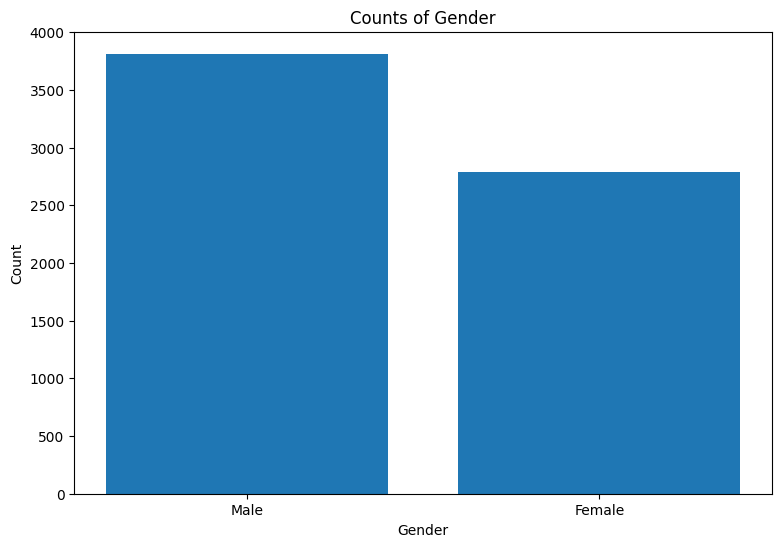

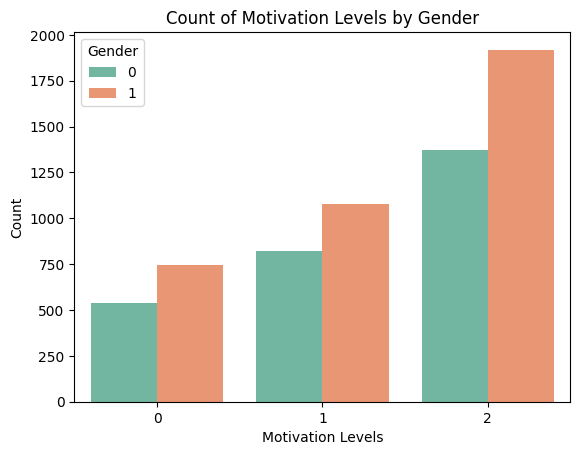

In [75]:
# Barplot to get insights of variables

# Switch values for gender. switch female and male to normal

df_gender_change = df['Gender'].replace({0: 'Female', 1: 'Male'})

gender_counts = df_gender_change.value_counts()

# Replace values in gender

plt.figure(figsize=(9, 6))
plt.bar(gender_counts.index, gender_counts.values)
plt.xlabel('Gender')
plt.ylabel('Count')
plt.title('Counts of Gender')
print(f"The counts of Gender {gender_counts}")
plt.show()

# Bar chart
# Distributions of motivation levels by Gender

sns.countplot(data=df_eda, x='Motivation_Level', hue='Gender', palette='Set2')
plt.title('Count of Motivation Levels by Gender')
plt.xlabel('Motivation Levels')
plt.ylabel('Count')
plt.legend(title='Gender')
plt.show()

# 1 For male
# 0 For female

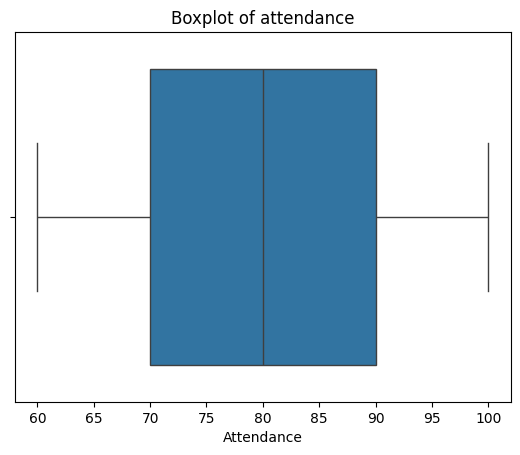

/tmp/ipykernel_4901/641257348.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Hours_Studied', palette='deep')


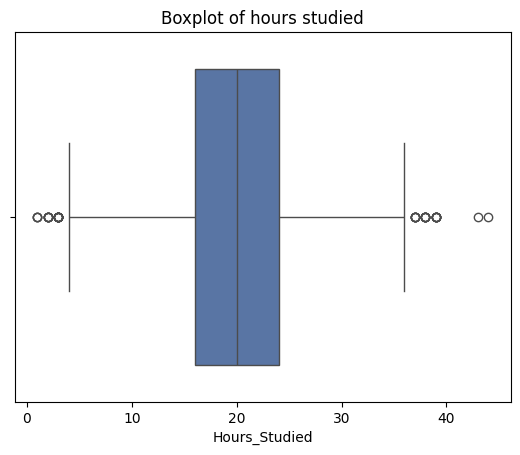

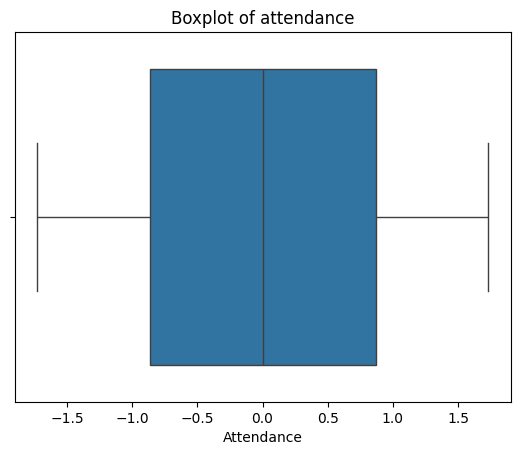

/tmp/ipykernel_4901/641257348.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_filtered, x='Total_Study_Hours', palette='deep')


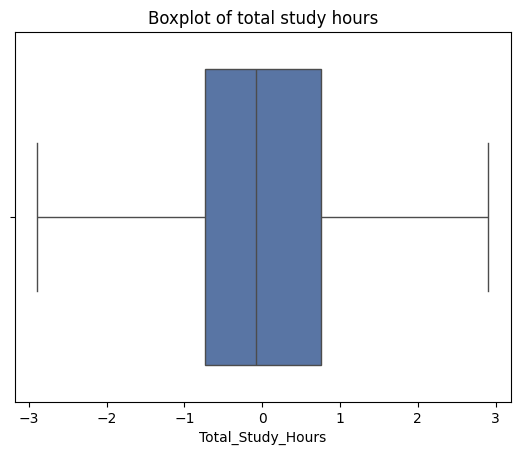

In [76]:
# Boxplots to find any anomalies

#Before removing code

sns.boxplot(data=df, x='Attendance')
plt.title('Boxplot of attendance')
plt.show()

sns.boxplot(data=df, x='Hours_Studied', palette='deep')
plt.title('Boxplot of hours studied')
plt.show()

# After removed

sns.boxplot(data=df_filtered, x='Attendance')
plt.title('Boxplot of attendance')
plt.show()

sns.boxplot(data=df_filtered, x='Total_Study_Hours', palette='deep')
plt.title('Boxplot of total study hours')
plt.show()

# Anomalies removed

Compare the performance metrics for gender in motivational levels and eg

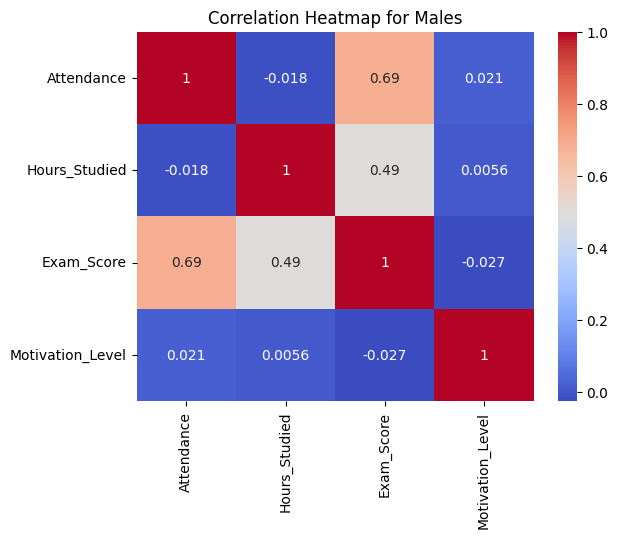

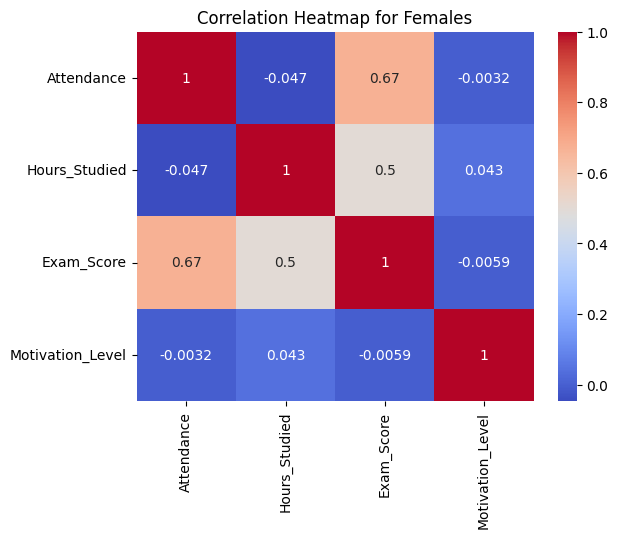

Descriptive Statistics for Males:
        Attendance  Hours_Studied   Exam_Score  Motivation_Level
count  3742.000000    3742.000000  3742.000000       3742.000000
mean     80.074025      19.964458    67.085249          1.313736
std      11.449930       5.783593     3.218240          0.783360
min      60.000000       4.000000    59.000000          0.000000
25%      70.000000      16.000000    65.000000          1.000000
50%      80.000000      20.000000    67.000000          2.000000
75%      90.000000      24.000000    69.000000          2.000000
max     100.000000      36.000000    75.000000          2.000000


In [77]:
#Correlation analysis

male_data = df_eda[df_eda['Gender'] == 1]
female_data = df_eda[df_eda['Gender'] == 0]

# Correlation heatmaps

# Bos male
sns.heatmap(male_data[['Attendance', 'Hours_Studied', 'Exam_Score', 'Motivation_Level']].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap for Males')
plt.show()

# Ah nis bos female
sns.heatmap(female_data[['Attendance', 'Hours_Studied', 'Exam_Score', 'Motivation_Level']].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap for Females')
plt.show()

print("Descriptive Statistics for Males:")
print(male_data[['Attendance', 'Hours_Studied', 'Exam_Score', 'Motivation_Level']].describe())

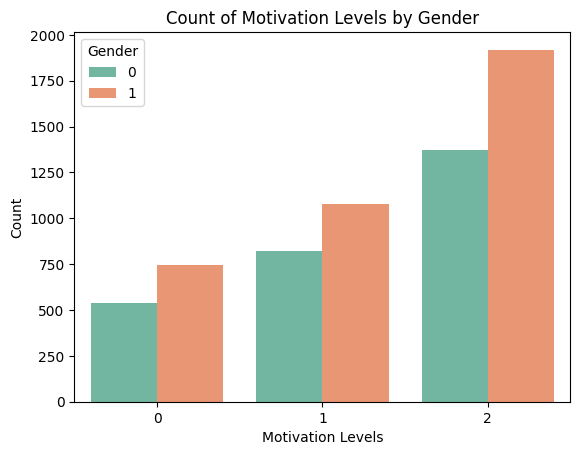

In [78]:
# Bar chart
# Distributions of motivation levels by Gender

sns.countplot(data=df_eda, x='Motivation_Level', hue='Gender', palette='Set2')
plt.title('Count of Motivation Levels by Gender')
plt.xlabel('Motivation Levels')
plt.ylabel('Count')
plt.legend(title='Gender')
plt.show()


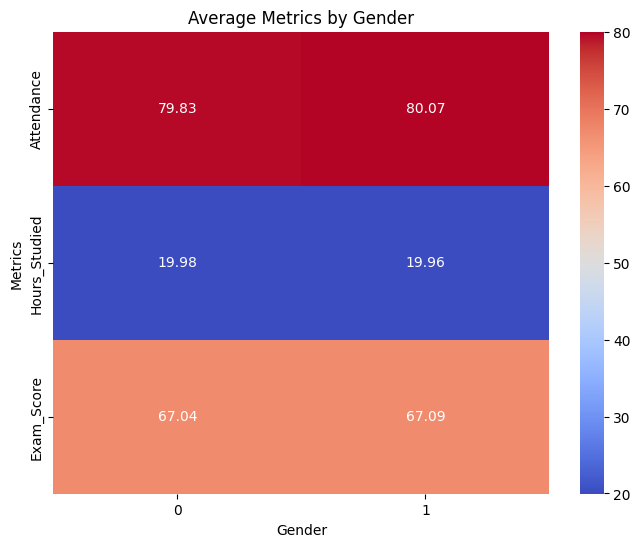

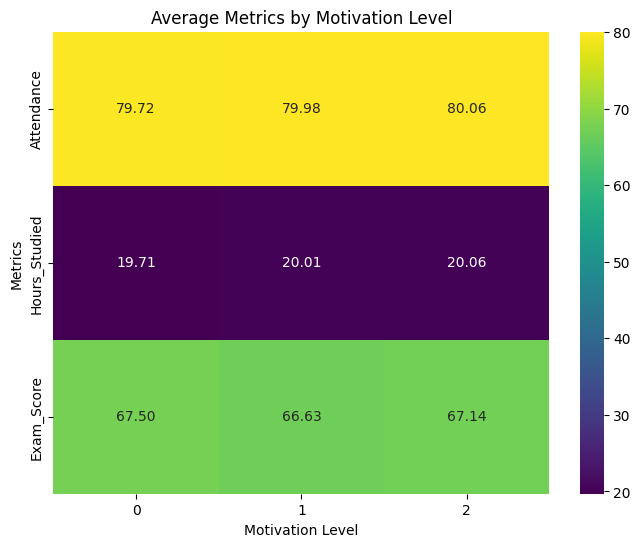

In [79]:

# Heatmap for Gender Trends
plt.figure(figsize=(8, 6))
sns.heatmap(trends_gender.T, annot=True, cmap='coolwarm', cbar=True, fmt='.2f')
plt.title('Average Metrics by Gender')
plt.ylabel('Metrics')
plt.xlabel('Gender')
plt.show()

# Heatmap for Motivation Trends
plt.figure(figsize=(8, 6))
sns.heatmap(trends_motivation.T, annot=True, cmap='viridis', cbar=True, fmt='.2f')
plt.title('Average Metrics by Motivation Level')
plt.ylabel('Metrics')
plt.xlabel('Motivation Level')
plt.show()


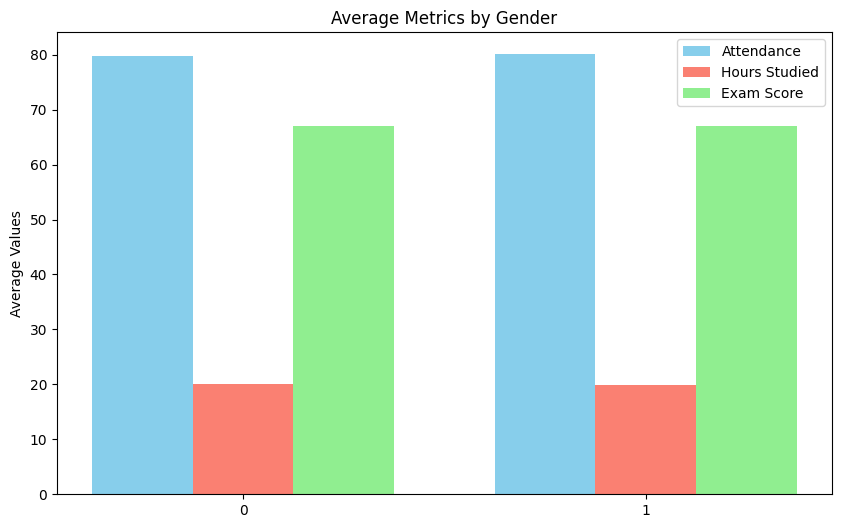

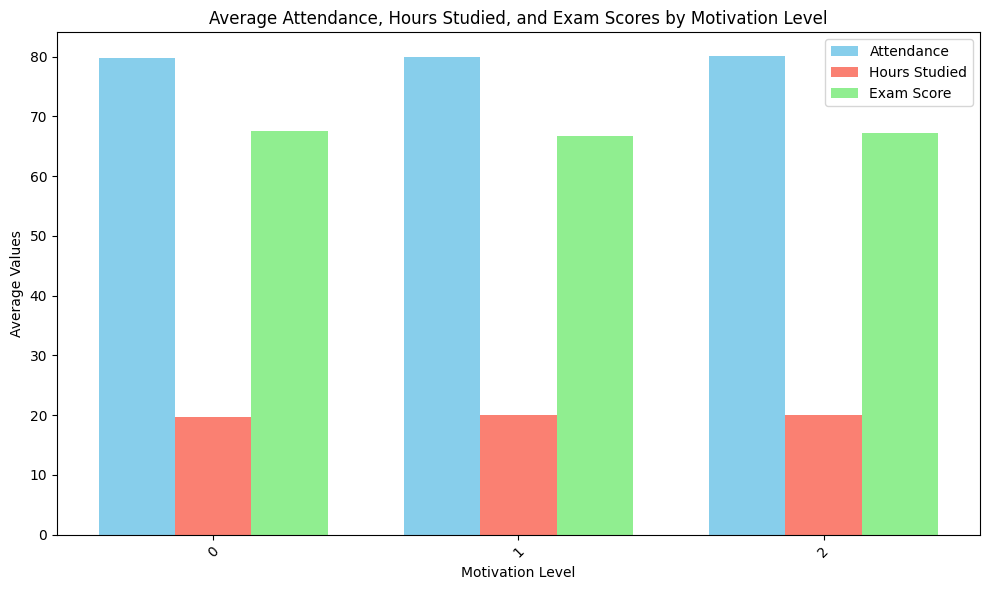

In [80]:
import numpy as np

# Gender trends
x = np.arange(len(trends_gender.index))  # Gender categories
width = 0.25  # Width of each bar

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(x - width, trends_gender['Attendance'], width, label='Attendance', color='skyblue')
ax.bar(x, trends_gender['Hours_Studied'], width, label='Hours Studied', color='salmon')
ax.bar(x + width, trends_gender['Exam_Score'], width, label='Exam Score', color='lightgreen')

ax.set_xticks(x)
ax.set_xticklabels(trends_gender.index)
ax.set_title('Average Metrics by Gender')
ax.set_ylabel('Average Values')
ax.legend()
plt.show()

# Motivation trend
x = np.arange(len(trends_motivation.index))  # Motivation Level categories
width = 0.25  # Width of each bar

fig, ax = plt.subplots(figsize=(10, 6))

# Plotting each metric
ax.bar(x - width, trends_motivation['Attendance'], width, label='Attendance', color='skyblue')
ax.bar(x, trends_motivation['Hours_Studied'], width, label='Hours Studied', color='salmon')
ax.bar(x + width, trends_motivation['Exam_Score'], width, label='Exam Score', color='lightgreen')

# Formatting the chart
ax.set_xticks(x)
ax.set_xticklabels(trends_motivation.index, rotation=45)  # Rotate x-axis labels if needed
ax.set_title('Average Attendance, Hours Studied, and Exam Scores by Motivation Level')
ax.set_ylabel('Average Values')
ax.set_xlabel('Motivation Level')
ax.legend()
plt.tight_layout()
plt.show()

# Model

Import and train our model

In [81]:

from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)
predictions = model.predict(X_test)

Model evaluation

In [82]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predictions from the trained model
predictions = model.predict(X_test)

# Evaluate the model
mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, predictions)

print(f"Mean Absolute Error (MAE): {mae}")
print(f"Mean Squared Error (MSE): {mse}")
print(f"Root Mean Squared Error (RMSE): {rmse}")
print(f"R-Squared (R²): {r2}")

Mean Absolute Error (MAE): 1.2477711166425811
Mean Squared Error (MSE): 5.676735021029303
Root Mean Squared Error (RMSE): 2.382589981727721
R-Squared (R²): 0.6114489609527773
